# Supplementary Figure 2f, 2g

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import PatchCollection
from matplotlib.gridspec import GridSpec
from matplotlib.patches import PathPatch
from matplotlib.ticker import FuncFormatter
from scipy.stats import ttest_1samp

sys.path.insert(0, '../..')
from paths import FIGURES, PREPARES

SAVE_PATH = Path('.')          # panels are written next to this notebook

## Configuration


In [3]:
ORDER = ['RFP', 'RHP', 'RW', 'RV', 'RM_M2', 'RFP_M2', 'LatM']

LABEL = {
    'RFP':    'FP S1',
    'RHP':    'HP S1',
    'RW':     'whisker S1',
    'RV':     'visual',
    'RM_M2':  'front_1',
    'RFP_M2': 'front_2',
    'LatM':   'lateral_1',
}

LATM_COLOR = '#936F65'   # palatte_dict has no LatM entry

# per-panel axis limits and star padding
PANELS = {
    'f': dict(col='mean_diff',
              ylabel='amplitude difference',
              title='neural amplitude shift (run2 minus rest1)',
              ylim=[-0.055, 0.15], percent=True,  star_pad_frac=0.05,
              outfile='figS2f-amplitude-corrected.svg'),
    'g': dict(col='std_diff',
              ylabel='rolling std difference',
              title='neural temporal variance shift (run2 minus rest1)',
              ylim=[-1.6, 1.0],   percent=False, star_pad_frac=0.07,
              outfile='figS2g-rollingstd-corrected.svg'),
}

## Load the pooled per-bout table

In [4]:
src = FIGURES / 'figure3' / 'stats_pooled_seedbox_current.pkl'
if not src.exists():
    raise SystemExit(f'missing {src} -- it is part of the deposited figures_data')

with open(src, 'rb') as f:
    pooled = pickle.load(f)

print(f'{len(pooled)} rows, columns: {list(pooled.columns)}')
print()
print('bouts per region x mouse:')
counts = pd.crosstab(pooled['region'], pooled['mouse'])
print(counts)

# every region must be n=199 (130+41+28); whisker falling back to 130 is the bug
# described at the top of this notebook.
per_region = counts.sum(axis=1)
assert set(per_region.unique()) == {199}, f'expected n=199 everywhere, got:\n{per_region}'
assert set(ORDER) == set(pooled['region'].unique()), 'region set does not match ORDER'
print()
print('CHECK  all 7 regions n=199 (whisker fix applied)  OK')

1393 rows, columns: ['std_diff', 'mean_diff', 'region', 'mouse']

bouts per region x mouse:
mouse   cm125  cm126  cm128
region                     
LatM      130     41     28
RFP       130     41     28
RFP_M2    130     41     28
RHP       130     41     28
RM_M2     130     41     28
RV        130     41     28
RW        130     41     28

CHECK  all 7 regions n=199 (whisker fix applied)  OK


## Plotting helpers

In [5]:
def star(p):
    for thr, s in ((1e-4, '****'), (1e-3, '***'), (1e-2, '**'), (5e-2, '*')):
        if p < thr:
            return s
    return 'n.s.'


def adjust_box_widths(ax, fac=0.3):
    """Narrow seaborn's boxes in place."""
    for c in ax.get_children():
        if isinstance(c, (PathPatch, PatchCollection)):
            p = c.get_path() if isinstance(c, PathPatch) else c.get_paths()[-1]
            verts_sub = p.vertices[:-1]
            xmin, xmax = np.min(verts_sub[:, 0]), np.max(verts_sub[:, 0])
            xmid, xhalf = 0.5 * (xmin + xmax), 0.5 * (xmax - xmin)
            xmin_new, xmax_new = xmid - fac * xhalf, xmid + fac * xhalf
            verts_sub[verts_sub[:, 0] == xmin, 0] = xmin_new
            verts_sub[verts_sub[:, 0] == xmax, 0] = xmax_new
            for line in ax.lines:
                try:
                    if np.all(line.get_xdata() == [xmin, xmax]):
                        line.set_xdata([xmin_new, xmax_new])
                except Exception:
                    pass


def palette():
    with open(str(PREPARES / 'config') + '/palatte_dict', 'rb') as f:
        pal = pickle.load(f)
    return {r: (pal.get(r) or LATM_COLOR) for r in ORDER}

In [6]:
def panel(pooled, col, ylabel, title, ylim, outfile,
          percent=False, star_pad_frac=0.05, save=True):
    pal = palette()

    data = pooled.copy()
    data['plot_region'] = data['region'].map(LABEL)
    order_lbl = [LABEL[r] for r in ORDER]
    pal_lbl = {LABEL[r]: pal[r] for r in ORDER}

    summary = []
    for r in ORDER:
        d = pooled[pooled.region == r][col].dropna()
        t, p = ttest_1samp(d, 0)
        summary.append({'region': r, 'label': LABEL[r], 'n': len(d),
                        'df': len(d) - 1, 't': t, 'p': p, 'star': star(p),
                        'mean': d.mean(), 's.d.': d.std(ddof=1),
                        "Cohen's d": d.mean() / d.std(ddof=1),
                        'y_max': d.max()})

    plt.style.use('default')
    plt.rcParams['svg.fonttype'] = 'none'
    fig = plt.figure(figsize=(16, 9), dpi=300)
    gs = GridSpec(100, 100)
    ax0 = fig.add_subplot(gs[15:45, 15:45])

    ax_violin = sns.violinplot(
        x='plot_region', y=col, data=data, order=order_lbl,
        palette=pal_lbl, density_norm='width', linewidth=0.5, inner=None,
        hue='plot_region', legend=False, ax=ax0)
    for violin in ax_violin.collections:
        bbox = violin.get_paths()[0].get_extents()
        x0, y0, width, height = bbox.bounds
        violin.set_clip_path(plt.Rectangle(
            (x0 - 0.06, y0), width / 2, height, transform=ax_violin.transData))

    sns.stripplot(x='plot_region', y=col, hue='plot_region', data=data,
                  order=order_lbl, palette=pal_lbl, dodge=False, size=2,
                  alpha=0.3, jitter=True, ax=ax0, legend=False)
    sns.boxplot(x='plot_region', y=col, data=data, order=order_lbl,
                showfliers=False, boxprops={'zorder': 500, 'facecolor': 'none'},
                linewidth=1.2, ax=ax0)
    adjust_box_widths(ax0, fac=0.3)

    ax0.set_xticks(range(len(order_lbl)))
    ax0.set_xticklabels(order_lbl, rotation=45, ha='right')
    if percent:
        ax0.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f'{x:.0%}'))

    pad = pooled[col].max() * star_pad_frac
    for i, s in enumerate(summary):
        ax0.text(i, s['y_max'] + pad, s['star'], ha='center', va='bottom',
                 color='black', fontsize=7)

    ax0.axhline(0, color='#3778bf', linewidth=1, linestyle='dashed', zorder=0)
    ax0.set_xlabel('cortical ROI region', fontsize=12)
    ax0.set_ylabel(ylabel, fontsize=12)
    ax0.set_title(title, fontsize=14)
    ax0.set_ylim(ylim)

    if save:
        out = SAVE_PATH / outfile
        fig.savefig(out, format='svg', bbox_inches='tight')
        print('wrote', out)
    plt.show()

    return pd.DataFrame(summary).drop(columns='y_max')

## Panel f — amplitude shift

wrote figS2f-amplitude-corrected.svg


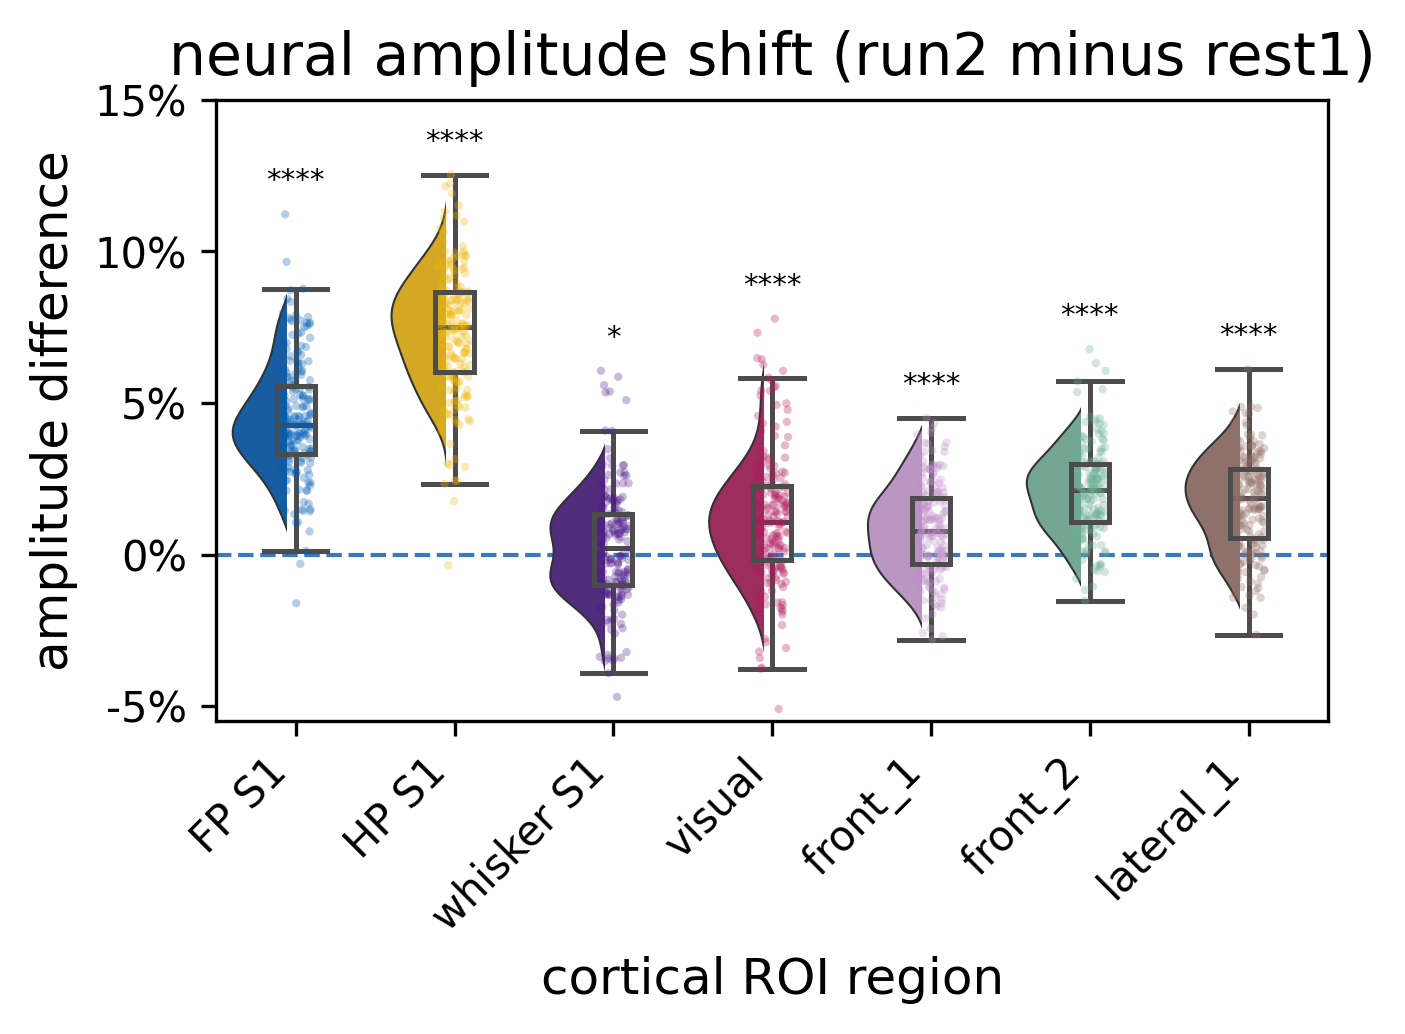

region      label   n  df     t          p star     mean    s.d.  Cohen's d
   RFP      FP S1 199 198 32.62  1.386e-81 ****  0.04474 0.01934      2.313
   RHP      HP S1 199 198 49.11 7.913e-113 ****  0.07339 0.02108      3.481
    RW whisker S1 199 198 1.989    0.04807    *  0.00264 0.01872      0.141
    RV     visual 199 198 7.499  2.116e-12 ****  0.01166 0.02193     0.5316
 RM_M2    front_1 199 198 7.664  7.895e-13 **** 0.008323 0.01532     0.5433
RFP_M2    front_2 199 198 19.96  2.671e-49 ****  0.02076 0.01467      1.415
  LatM  lateral_1 199 198 15.28  2.392e-35 ****  0.01721 0.01588      1.084


In [7]:
stats_f = panel(pooled, **PANELS['f'])
print(stats_f.to_string(index=False, float_format=lambda v: f'{v:.4g}'))

## Panel g — temporal-variance shift

wrote figS2g-rollingstd-corrected.svg


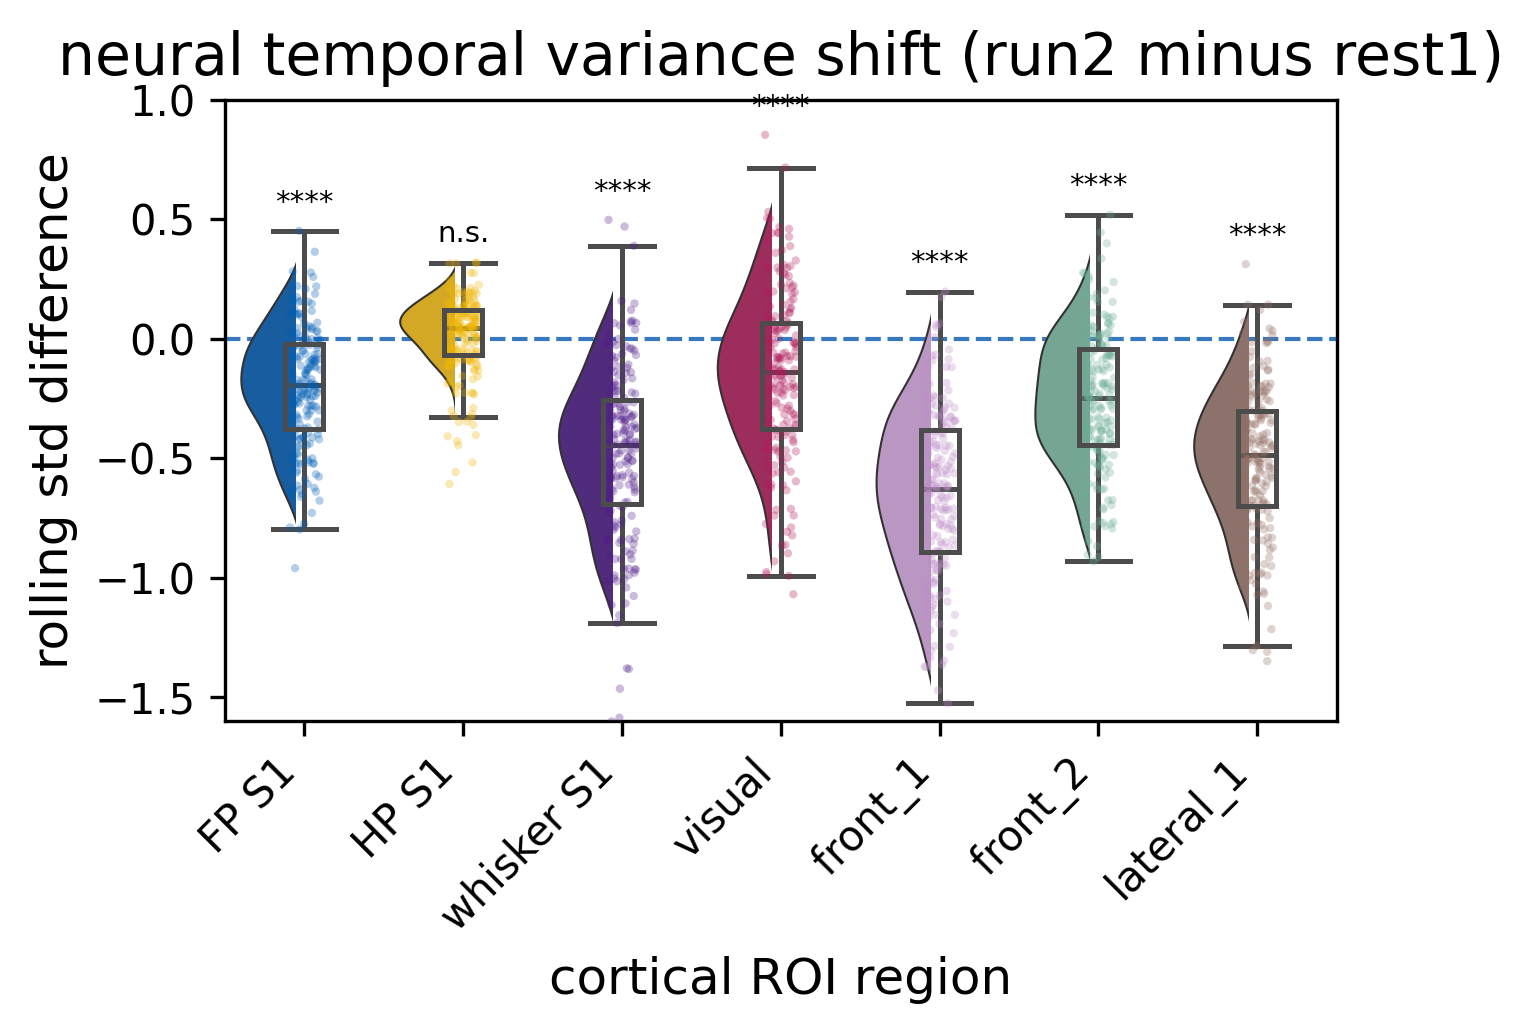

region      label   n  df      t         p star    mean   s.d.  Cohen's d
   RFP      FP S1 199 198 -11.24 5.418e-23 **** -0.2038 0.2558    -0.7968
   RHP      HP S1 199 198 0.9668    0.3348 n.s. 0.01133 0.1653    0.06854
    RW whisker S1 199 198 -18.67 1.586e-45 **** -0.4786 0.3617     -1.323
    RV     visual 199 198 -6.105 5.342e-09 **** -0.1528  0.353    -0.4327
 RM_M2    front_1 199 198 -25.94 1.301e-65 **** -0.6465 0.3515     -1.839
RFP_M2    front_2 199 198 -12.59 4.391e-27 **** -0.2574 0.2884    -0.8925
  LatM  lateral_1 199 198 -22.75 3.883e-57 **** -0.5055 0.3135     -1.613


In [8]:
stats_g = panel(pooled, **PANELS['g'])
print(stats_g.to_string(index=False, float_format=lambda v: f'{v:.4g}'))